# Humidity Level and Mould Risk

**BQ2:** How can seasonal weather changes, air-con performance and humidity levels be analysed to detect zones that are at risk of air-con degradation or mould growth?

This notebook covers the **mould half** for the 20 study zones (**Floors 3-7, zones 1, 2, 4, 5**). It makes:

| Output | Used for |
|---|---|
| `time_of_wetness.png` | Slide 2 (left): high humidity exposure by zone |
| `damp_drivers.png` | Slide 2 (right): reasons for high humidity by zone |
| `zone_mould_metrics.csv` | Input to the risk matrix in `bq2_risk_matrix.ipynb` |

**Why surface RH, not room RH?** RH rises whenever air cools, even with no extra moisture, so it can't rank zones. This notebook uses **humidity ratio** (grams of water per kg of air) for moisture and **surface RH** (a surface 2 °C cooler than the room) for mould risk.

**Important:** the sensors measure room air, not surfaces, and no mould inspections exist. Results are **risk indicators for inspection priority**, not mould findings.

## 1. Load the data

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Project root = the folder holding data-cleaning/; this BQ2 folder sits in analytics/ inside it
here = Path.cwd().resolve()
repo_root = next(p for p in (here, *here.parents) if (p / "data-cleaning").is_dir())
analysis_dir = repo_root / "analytics/mould-ac-degradation"
sys.path.insert(0, str(analysis_dir / "src"))
helper_notebook = analysis_dir / "bq2_utils.ipynb"
get_ipython().run_line_magic("run", f'-i "{helper_notebook}"')

sys.path.insert(0, str(repo_root / BASELINE_CODE_DIR))
from humidity_risk_baseline import load_bangkok_era5_weather
weather = load_bangkok_era5_weather(repo_root / WEATHER_CSV)
df = merge_weather(load_zone_hourly(repo_root / ZONE_HOURLY_CSV), weather)
df["zone_id"] = "F" + df["floor"].astype(str) + "-Z" + df["zone"].astype(str)
df["valid"] = df["temp_C"].notna() & df["rh_pct"].notna()

OUT_DIR = analysis_dir / "outputs/bq2-humidity"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Settings
MOULD_RH = 80                     # surface RH (%) at which mould growth becomes possible
SURFACE_DROP_C = 2                # main scenario: surface 2 °C cooler than the room air
WINDOWS = [("2018-07-01", "2018-09-30 23:00"),     # all 2018 sensor data (it stops mid-Sep)
           ("2019-03-07", "2019-10-21 23:00")]     # 2019 until Floor 6's data ends

def in_window(dates):
    """True for timestamps inside either window (both years together)."""
    dates = pd.Series(dates)
    return np.any([dates.between(a, b) for a, b in WINDOWS], axis=0)

BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#a3a29c", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})

suspect = set(df.loc[df["suspect_sensor"], "zone_id"])           # F5-Z1: unusually cold sensor
common = df[in_window(df["Date"])]
v = common[common["valid"]].copy()
coverage = pd.DataFrame({"rh_coverage_pct": df.groupby("zone_id")["valid"].mean() * 100,
                         "common_window_coverage_pct": common.groupby("zone_id")["valid"].mean() * 100}).round(1)
assert set(df["floor"]) <= {3, 4, 5, 6, 7} and set(df["zone"]) <= {1, 2, 4, 5}
print(f"Scope: floors {sorted(df['floor'].unique().tolist())}, zones {sorted(df['zone'].unique().tolist())}")
print(f"{df['zone_id'].nunique()} zones; combined-window coverage {coverage['common_window_coverage_pct'].min():.0f}-"
      f"{coverage['common_window_coverage_pct'].max():.0f}% (lowest: "
      f"{', '.join(coverage['common_window_coverage_pct'].nsmallest(4).index)})")

Scope: floors [3, 4, 5, 6, 7], zones [1, 2, 4, 5]
20 zones; combined-window coverage 65-93% (lowest: F5-Z2, F5-Z1, F4-Z4, F3-Z5)


**What this shows:** all 20 zones load. Most have about 86-93% of hours in the combined window; F5-Z2, F5-Z1, F4-Z4 and F3-Z5 have less (65-73%), so their results are flagged as lower confidence in the zone table.

## 2. High humidity exposure by zone (slide 2, left)

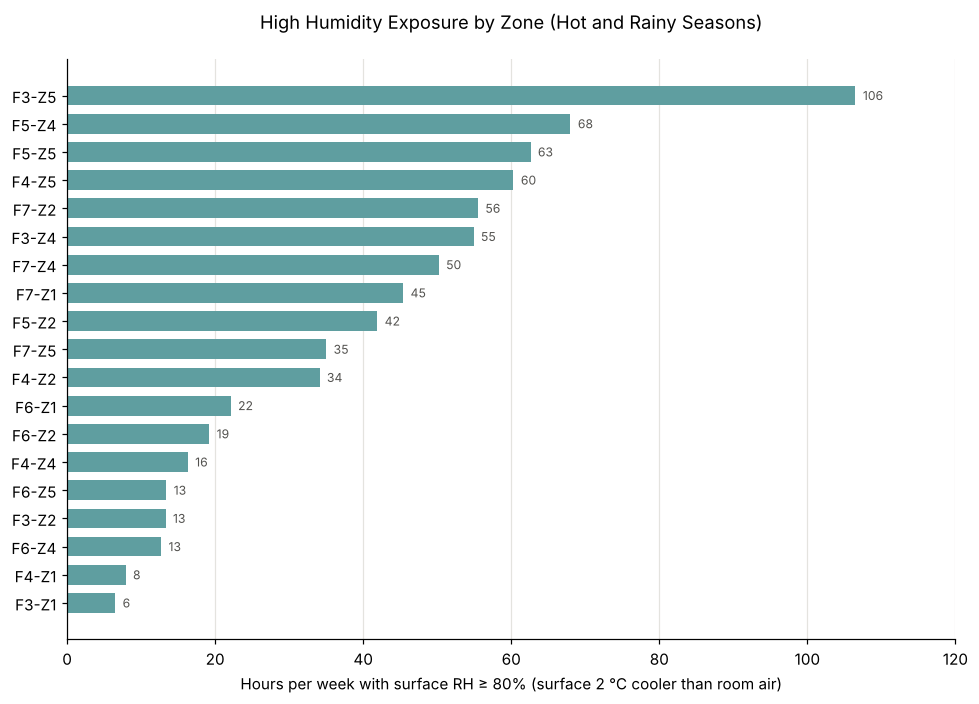

In [2]:
# Surface RH: humidity at a wall or desk assumed 2 °C cooler than the room air
v["surface_rh"] = surface_rh_pct(v["indoor_dew_C"], v["temp_C"] - SURFACE_DROP_C)

def hours_per_week_wet(s):
    return (s >= MOULD_RH).mean() * 168

def peak_30_day_mean(g):
    return g.set_index("Date")["surface_rh"].sort_index().rolling("30D", min_periods=360).mean().max()

mould = pd.DataFrame({
    "time_of_wetness_h": v.groupby("zone_id")["surface_rh"].apply(hours_per_week_wet),
    "peak_30d_surface_rh": v.groupby("zone_id")[["Date", "surface_rh"]].apply(peak_30_day_mean),
}).round(1)
mould["meets_30d_criterion"] = mould["peak_30d_surface_rh"] >= MOULD_RH       # mould-risk rule
mould["mould_priority"] = np.where(mould.index.isin(suspect), "Check sensor first",
                                   np.where(mould["meets_30d_criterion"], "Inspect first", "Monitor"))

# Chart (slide 2, left): F5-Z1 left out (faulty sensor)
order = mould.drop(index=list(suspect)).sort_values("time_of_wetness_h").index

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(order, mould.loc[order, "time_of_wetness_h"], color="cadetblue", height=0.7)
for z in order:
    ax.text(mould.loc[z, "time_of_wetness_h"] + 1, z, f"{mould.loc[z, 'time_of_wetness_h']:.0f}",
            va="center", fontsize=8, color=INK)
ax.set_xlim(0, 120)
ax.set_xlabel(f"Hours per week with surface RH ≥ {MOULD_RH}% (surface {SURFACE_DROP_C} °C cooler than room air)")
ax.set_title("High Humidity Exposure by Zone (Hot and Rainy Seasons)", loc="center", pad=20)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "time_of_wetness.png", bbox_inches="tight")
plt.show()

**What this shows:**

- **Hours per week with surface RH ≥ 80%**, over the hot and rainy months of both years (Jul-Sep 2018 and Mar-Oct 2019). Every zone uses the same months, so the comparison between zones is fair.
- **The dampest zones** (F3-Z5, F5-Z4, F5-Z5, F4-Z5, F7-Z2, F3-Z4) have high surface humidity for about 55-106 hours a week; the driest (F3-Z1, F4-Z1) under 10.
- **"Inspect first"** (used by the risk matrix) means the surface stayed at 80% RH or more on average for a whole 30-day period.
- **F5-Z1 is left out**: its sensor reads too cold to be reliable.

## 3. Reasons for high humidity by zone (slide 2, right)

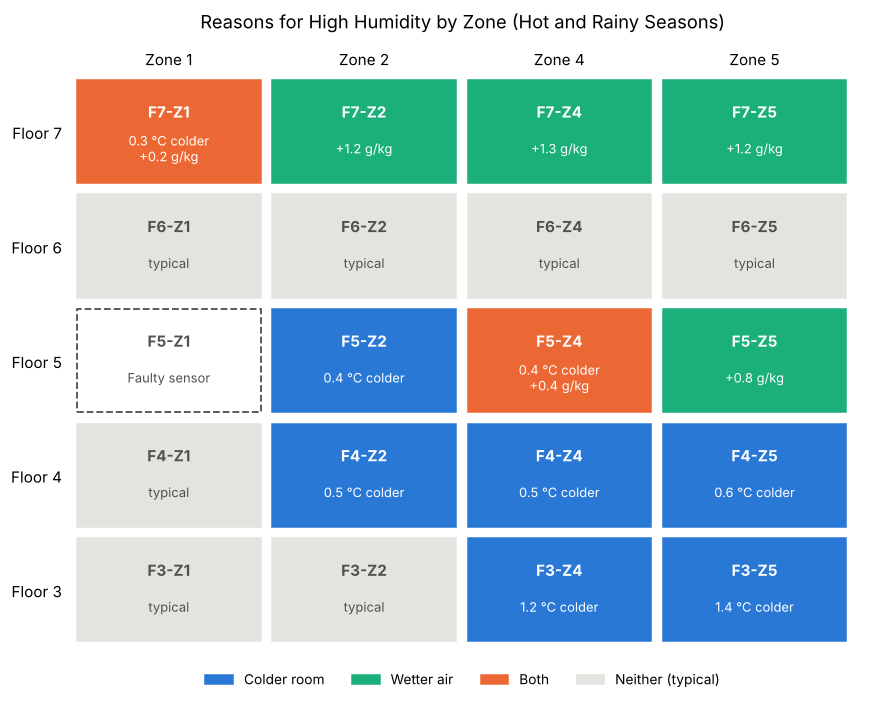

,damp_hours,moisture_vs_typical_gkg,temp_vs_typical_C,damp_driver
zone_id,,,,
F5-Z4,68.0,0.43,-0.44,Both
F7-Z1,45.4,0.24,-0.35,Both
F3-Z5,106.5,0.16,-1.45,Colder room
F4-Z5,60.3,0.04,-0.64,Colder room
F3-Z4,54.9,-0.36,-1.16,Colder room
F5-Z2,41.9,0.06,-0.37,Colder room
F4-Z2,34.1,-0.13,-0.54,Colder room
F4-Z4,16.3,-0.70,-0.54,Colder room
F6-Z1,22.1,0.02,0.40,Neither (typical)


In [3]:
# Is each zone damp because of wetter air or a colder room? Compare it with the typical zone at the same hour.
v_ok = v[~v["zone_id"].isin(suspect)].copy()                                   # F5-Z1 left out (faulty sensor)
v_ok["typical_w"] = v_ok.groupby("Date")["indoor_w_gkg"].transform("median")   # 19-zone median moisture
v_ok["typical_T"] = v_ok.groupby("Date")["temp_C"].transform("median")         # 19-zone median temperature
drivers = pd.DataFrame({
    "moisture_vs_typical_gkg": (v_ok["indoor_w_gkg"] - v_ok["typical_w"]).groupby(v_ok["zone_id"]).mean(),
    "temp_vs_typical_C": (v_ok["temp_C"] - v_ok["typical_T"]).groupby(v_ok["zone_id"]).mean(),
}).round(2)
drivers.insert(0, "damp_hours", mould["time_of_wetness_h"])
wetter = drivers["moisture_vs_typical_gkg"] > 0.2      # differences of 0.2 or less count as typical
colder = drivers["temp_vs_typical_C"] < -0.2
drivers["damp_driver"] = np.select([wetter & colder, wetter, colder], ["Both", "Wetter air", "Colder room"],
                                   default="Neither (typical)")

# Chart: building grid (floors x zones), each box coloured by the cause of dampness
DRIVER_COLOR = {"Colder room": BLUE, "Wetter air": "#1baf7a", "Both": ORANGE, "Neither (typical)": "#e4e3df"}
FLOORS, ZONES = [7, 6, 5, 4, 3], [1, 2, 4, 5]                 # top floor at the top

def reason(r):
    parts = []
    if r["temp_vs_typical_C"] < -0.2:
        parts.append(f"{-r['temp_vs_typical_C']:.1f} °C colder")
    if r["moisture_vs_typical_gkg"] > 0.2:
        parts.append(f"+{r['moisture_vs_typical_gkg']:.1f} g/kg")
    return "\n".join(parts) or "typical"

fig, ax = plt.subplots(figsize=(8, 6.5))
for i, f in enumerate(FLOORS):
    for j, zn in enumerate(ZONES):
        z = f"F{f}-Z{zn}"
        if z not in drivers.index:                            # F5-Z1: faulty sensor, dashed white box
            ax.add_patch(plt.Rectangle((j, -i), 0.94, 0.9, facecolor="white", edgecolor=INK,
                                       linestyle="--", linewidth=1.2))
            ax.text(j + 0.47, -i + 0.62, z, ha="center", va="center", fontsize=10, fontweight="bold", color=INK)
            ax.text(j + 0.47, -i + 0.3, "Faulty sensor", ha="center", va="center", fontsize=8.5, color=INK)
            continue
        r = drivers.loc[z]
        ax.add_patch(plt.Rectangle((j, -i), 0.94, 0.9, color=DRIVER_COLOR[r["damp_driver"]]))
        text_color = INK if r["damp_driver"] == "Neither (typical)" else "white"
        ax.text(j + 0.47, -i + 0.62, z, ha="center", va="center", fontsize=10, fontweight="bold", color=text_color)
        ax.text(j + 0.47, -i + 0.3, reason(r), ha="center", va="center", fontsize=8.5, color=text_color)
ax.set_xlim(-0.05, len(ZONES))
ax.set_ylim(-len(FLOORS) + 0.95, 0.95)
ax.set_xticks([j + 0.47 for j in range(len(ZONES))], [f"Zone {zn}" for zn in ZONES])
ax.set_yticks([-i + 0.45 for i in range(len(FLOORS))], [f"Floor {f}" for f in FLOORS])
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Reasons for High Humidity by Zone (Hot and Rainy Seasons)", loc="center", pad=30)
ax.legend(handles=[Patch(color=c, label=d) for d, c in DRIVER_COLOR.items()], loc="upper center",
          bbox_to_anchor=(0.5, -0.02), ncol=4, frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(OUT_DIR / "damp_drivers.png", bbox_inches="tight")
plt.show()
drivers.sort_values(["damp_driver", "damp_hours"], ascending=[True, False])

   **What this shows:**

   - **Colder room (7 zones, mostly Floors 3-4):** typical moisture but 0.3-1.4 °C colder than other zones, led by F3-Z5 (106 h, 1.4 °C colder). Check AC setpoints / overcooling, or whether the sensors read cold. Matches Track B: F3-Z4's AC runs more continuously.
   - **Wetter air (4 zones, mostly Floor 7):** up to 1.3 g/kg more moisture than other zones. Check ventilation, moisture sources and AC dehumidification. Matches Track B's F7-Z2 finding.
   - **Both (F5-Z4, F7-Z1)** and **typical (7 zones, mostly Floor 6).**

## 4. Zone table (handover to the risk matrix)

In [4]:
table = mould.join(coverage)
table["suspect_sensor"] = table.index.isin(suspect)
table["note"] = ""
table.loc[table["suspect_sensor"], "note"] += "Suspect sensor (unusually cold readings); "
table.loc[table["common_window_coverage_pct"] < 75, "note"] += "Low humidity coverage in window; "
table["note"] = table["note"].str.rstrip("; ")

table["order"] = table["mould_priority"].map({"Inspect first": 1, "Monitor": 2, "Check sensor first": 3})
table = table.sort_values(["order", "time_of_wetness_h"], ascending=[True, False]).drop(columns="order")
table = table.rename_axis("zone_id").reset_index()
table.insert(1, "floor", table["zone_id"].str[1].astype(int))
table.insert(2, "zone", table["zone_id"].str[-1].astype(int))
table.to_csv(OUT_DIR / "zone_mould_metrics.csv", index=False)
table[["zone_id", "mould_priority", "time_of_wetness_h", "peak_30d_surface_rh", "note"]]

,zone_id,mould_priority,time_of_wetness_h,peak_30d_surface_rh,note
0,F3-Z5,Inspect first,106.5,86.1,Low humidity coverage in window
1,F5-Z4,Inspect first,68.0,82.8,
2,F5-Z5,Inspect first,62.6,81.7,
3,F4-Z5,Inspect first,60.3,82.5,
4,F7-Z2,Inspect first,55.5,83.0,
5,F3-Z4,Inspect first,54.9,81.8,
6,F7-Z4,Inspect first,50.2,80.5,
7,F7-Z1,Inspect first,45.4,82.3,
8,F4-Z2,Inspect first,34.1,80.4,
9,F5-Z2,Monitor,41.9,79.5,Low humidity coverage in window


## 5. Findings and limitations

1. **Surface humidity ranks the zones.** F3-Z5, F5-Z4, F5-Z5, F4-Z5, F7-Z2 and F3-Z4 have high surface humidity for the most hours.
2. **Two causes need two fixes:** colder rooms (mostly Floors 3-4) and wetter air (mostly Floor 7). `bq2_risk_matrix.ipynb` checks which of the wetter-air zones are caused by the AC.

**Limitations:** room-air sensors, not surfaces, so the 2 °C surface drop is an assumption and the **ranking** matters more than the exact hours. The 80% / 30-day rule follows the older ASHRAE 160 approach. Sensor calibration across the 2018-19 firmware update is unverified. No occupancy, setpoint or mould-inspection records exist, so these results show **where to inspect first**, not confirmed mould.